# Bayesian Optimization as Local Search within an EDA

This notebook investigates the effectiveness of using **Bayesian Optimization (BO)** as a local refinement strategy within an **Estimation of Distribution Algorithm (EDA)**.

The EDA serves as the main optimization algorithm, exploring the search space and identifying promising solutions. BO is then applied as a local search method to further refine these solutions by exploring their neighboring regions.

To evaluate the impact of incorporating BO, we will implement and compare three EDA variants:

1. **Standard EDA:** A baseline implementation without any local search.
2. **EDA with Classical Local Search:** An EDA enhanced with `ScipyLocalSearch`, using the L-BFGS-B optimization method for local refinement.
3. **EDA with Bayesian Optimization:** An EDA that uses BO as a local search strategy to improve the solutions found by the EDA.

The goal is to assess whether BO provides an effective local refinement mechanism and how its performance compares to both the standard EDA and a traditional gradient-based local search approach.

In [62]:

from IPython import get_ipython

ipython = get_ipython()
if ipython is not None:
    ipython.run_line_magic("matplotlib", "inline")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from IPython.display import display
from tqdm import tqdm
from scipy.optimize import minimize
from skopt import Optimizer
from skopt.space import Real

# EDA framework
from pateda import GaussianUMDA
from pateda.functions.continuous.toy_functions import (
    ackley, rastrigin, rosenbrock, sphere
)


# Plot configuration
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

In [63]:
# General parameters
N_DIMS = 5
POP_SIZE = 30
MAX_EVALUATIONS = 3000
N_RUNS = 10

BENCHMARKS = {
    "sphere": (sphere, (-5.12, 5.12)),
    "rastrigin": (rastrigin, (-5.12, 5.12)),
    "ackley": (ackley, (-32.768, 32.768)),
    "rosenbrock": (rosenbrock, (-5.0, 10.0)),
}

# Plain EDA

The plain EDA uses a univariate Gaussian model, selects the best half of the population, and keeps the best solution between generations. With a population of 30, 100 evaluated populations use exactly the 3,000-evaluation budget.

The benchmark value is negated because `pateda` maximizes fitness while these benchmarks are minimization problems. The evaluation counter prevents a run from exceeding the budget.

In [64]:
N_GENERATIONS = MAX_EVALUATIONS // POP_SIZE - 1
assert MAX_EVALUATIONS % POP_SIZE == 0

In [65]:
def run_plain_eda(benchmark, objective, bounds, seed):
    evaluations = 0

    def fitness(x):
        nonlocal evaluations
        if evaluations >= MAX_EVALUATIONS:
            raise RuntimeError("Evaluation budget exceeded")
        evaluations += 1
        return -float(objective(x))

    eda = GaussianUMDA(
        n_vars=N_DIMS,
        bounds=bounds,
        fitness_func=fitness,
        pop_size=POP_SIZE,
        n_gen=N_GENERATIONS,
        selection_ratio=0.5,
        elitism=True,
        random_seed=seed,
    )
    stats, _ = eda.run(verbose=False)

    return {
        "benchmark": benchmark,
        "run": seed + 1,
        "seed": seed,
        "evaluations": evaluations,
        "best_value": -stats.best_fitness_overall,
    }

## Run and save

Each benchmark is run ten times with seeds 0 to 9. The CSV stores the benchmark, run number, seed, evaluations used, and best objective value found.

In [66]:
rows = []

for benchmark, (objective, bounds) in BENCHMARKS.items():
    for seed in tqdm(range(N_RUNS), desc=f"Plain EDA - {benchmark}"):
        rows.append(run_plain_eda(benchmark, objective, bounds, seed))

results = pd.DataFrame(rows)
output_path = Path("results/plain_eda_results.csv")
output_path.parent.mkdir(parents=True, exist_ok=True)
results.to_csv(output_path, index=False)
results

Plain EDA - rosenbrock: 100%|██████████| 10/10 [00:00<00:00, 90.82it/s]


,benchmark,run,seed,evaluations,best_value
0,sphere,1,0,3000,1.581969e-06
1,sphere,2,1,3000,4.887812e-05
2,sphere,3,2,3000,5.299653e-11
3,sphere,4,3,3000,1.027719e-16
4,sphere,5,4,3000,3.914002e-18
5,sphere,6,5,3000,1.637342e-21
6,sphere,7,6,3000,1.108370e-08
7,sphere,8,7,3000,1.440888e-21
8,sphere,9,8,3000,4.228802e-16
9,sphere,10,9,3000,1.195814e-21


# EDA with Classical Local Search

This version applies L-BFGS-B to the best 25% of each new population. Local search can use at most 40 evaluations per generation and 10 evaluations per selected solution.

EDA sampling and local search share the same 3,000-evaluation counter. A solution is replaced only when local search finds a better objective value.

In [67]:
LOCAL_SUBSET_FRACTION = 0.25
LOCAL_GENERATION_BUDGET = 40
LOCAL_SOLUTION_BUDGET = 10
N_CLASSICAL_GENERATIONS = (
    int(np.ceil(MAX_EVALUATIONS / (POP_SIZE + LOCAL_GENERATION_BUDGET))) - 1
)


class BudgetedScipyLocalSearch:
    def optimize(self, population, fitness, fitness_func, cardinality, **params):
        new_population = population.copy()
        new_fitness = fitness.copy()
        n_selected = max(1, int(np.ceil(len(population) * LOCAL_SUBSET_FRACTION)))
        selected = np.argsort(fitness.ravel())[::-1][:n_selected]
        remaining = min(LOCAL_GENERATION_BUDGET, params["remaining_evaluations"]())
        scipy_bounds = list(zip(cardinality[0], cardinality[1]))
        total_evaluations = 0

        for index in selected:
            budget = min(LOCAL_SOLUTION_BUDGET, remaining)
            if budget <= 0:
                break

            best_x = population[index].copy()
            best_fitness = float(fitness[index, 0])
            evaluations = 0

            def objective(x):
                nonlocal evaluations, best_x, best_fitness
                if evaluations >= budget:
                    return 1e100
                value = float(fitness_func(x))
                evaluations += 1
                if value > best_fitness:
                    best_x, best_fitness = x.copy(), value
                return -value

            minimize(
                objective,
                best_x,
                method="L-BFGS-B",
                bounds=scipy_bounds,
                options={"maxiter": budget, "maxfun": budget},
            )
            new_population[index] = best_x
            new_fitness[index, 0] = best_fitness
            remaining -= evaluations
            total_evaluations += evaluations

        return new_population, new_fitness, total_evaluations

In [68]:
def run_eda_with_classical_ls(benchmark, objective, bounds, seed):
    evaluations = 0

    def fitness(x):
        nonlocal evaluations
        if evaluations >= MAX_EVALUATIONS:
            raise RuntimeError("Evaluation budget exceeded")
        evaluations += 1
        return -float(objective(x))

    eda = GaussianUMDA(
        n_vars=N_DIMS,
        bounds=bounds,
        fitness_func=fitness,
        pop_size=POP_SIZE,
        n_gen=N_CLASSICAL_GENERATIONS,
        selection_ratio=0.5,
        elitism=True,
        random_seed=seed,
    )
    eda._eda.components.local_opt = BudgetedScipyLocalSearch()
    eda._eda.components.local_opt_params = {
        "remaining_evaluations": lambda: MAX_EVALUATIONS - evaluations
    }
    stats, _ = eda.run(verbose=False)

    return {
        "benchmark": benchmark,
        "run": seed + 1,
        "seed": seed,
        "evaluations": evaluations,
        "best_value": -stats.best_fitness_overall,
    }

## Run and save

Run the classical local-search variant ten times per benchmark and save the results separately.

In [69]:
classical_rows = []

for benchmark, (objective, bounds) in BENCHMARKS.items():
    seeds = tqdm(range(N_RUNS), desc=f"EDA + L-BFGS-B - {benchmark}")
    for seed in seeds:
        classical_rows.append(
            run_eda_with_classical_ls(benchmark, objective, bounds, seed)
        )

classical_results = pd.DataFrame(classical_rows)
classical_output_path = Path("results/classical_ls_results.csv")
classical_output_path.parent.mkdir(parents=True, exist_ok=True)
classical_results.to_csv(classical_output_path, index=False)
classical_results

EDA + L-BFGS-B - rosenbrock: 100%|██████████| 10/10 [00:00<00:00, 26.62it/s]


,benchmark,run,seed,evaluations,best_value
0,sphere,1,0,3000,1.090496e-12
1,sphere,2,1,3000,6.110097e-13
2,sphere,3,2,3000,1.096604e-12
3,sphere,4,3,3000,1.297546e-12
4,sphere,5,4,3000,3.285617e-12
5,sphere,6,5,3000,2.524401e-12
6,sphere,7,6,3000,5.121850e-13
7,sphere,8,7,3000,5.610094e-12
8,sphere,9,8,3000,7.564335e-12
9,sphere,10,9,3000,1.746683e-11


# EDA with Bayesian Optimization

This version replaces L-BFGS-B with Bayesian Optimization using a Gaussian process and Expected Improvement. BO searches a trust region covering 15% of the global range around each selected solution.

It uses the same population subset and local-search budgets as the classical variant. The known centre initializes the surrogate without spending another objective evaluation.

In [70]:
BO_TRUST_REGION = 0.15
N_BO_GENERATIONS = N_CLASSICAL_GENERATIONS


class BudgetedBayesianLocalSearch:
    def __init__(self, seed):
        self.rng = np.random.default_rng(seed)

    def optimize(self, population, fitness, fitness_func, cardinality, **params):
        new_population = population.copy()
        new_fitness = fitness.copy()
        n_selected = max(1, int(np.ceil(len(population) * LOCAL_SUBSET_FRACTION)))
        selected = np.argsort(fitness.ravel())[::-1][:n_selected]
        remaining = min(LOCAL_GENERATION_BUDGET, params["remaining_evaluations"]())
        global_lower, global_upper = cardinality
        global_range = global_upper - global_lower
        total_evaluations = 0

        for index in selected:
            budget = min(LOCAL_SOLUTION_BUDGET, remaining)
            if budget <= 0:
                break

            centre = population[index].copy()
            best_x = centre.copy()
            best_fitness = float(fitness[index, 0])
            local_lower = np.maximum(
                global_lower, centre - BO_TRUST_REGION * global_range
            )
            local_upper = np.minimum(
                global_upper, centre + BO_TRUST_REGION * global_range
            )
            dimensions = [
                Real(float(lower), float(upper))
                for lower, upper in zip(local_lower, local_upper)
            ]
            optimizer = Optimizer(
                dimensions=dimensions,
                base_estimator="GP",
                acq_func="EI",
                n_initial_points=1,
                random_state=int(self.rng.integers(0, 2**32 - 1)),
            )
            optimizer.tell(centre.tolist(), -best_fitness)

            for _ in range(budget):
                candidate = np.asarray(optimizer.ask(), dtype=float)
                value = float(fitness_func(candidate))
                optimizer.tell(candidate.tolist(), -value)
                if value > best_fitness:
                    best_x, best_fitness = candidate.copy(), value

            new_population[index] = best_x
            new_fitness[index, 0] = best_fitness
            remaining -= budget
            total_evaluations += budget

        return new_population, new_fitness, total_evaluations

In [71]:
def run_eda_with_bo(benchmark, objective, bounds, seed):
    evaluations = 0

    def fitness(x):
        nonlocal evaluations
        if evaluations >= MAX_EVALUATIONS:
            raise RuntimeError("Evaluation budget exceeded")
        evaluations += 1
        return -float(objective(x))

    eda = GaussianUMDA(
        n_vars=N_DIMS,
        bounds=bounds,
        fitness_func=fitness,
        pop_size=POP_SIZE,
        n_gen=N_BO_GENERATIONS,
        selection_ratio=0.5,
        elitism=True,
        random_seed=seed,
    )
    eda._eda.components.local_opt = BudgetedBayesianLocalSearch(seed)
    eda._eda.components.local_opt_params = {
        "remaining_evaluations": lambda: MAX_EVALUATIONS - evaluations
    }
    stats, _ = eda.run(verbose=False)

    return {
        "benchmark": benchmark,
        "run": seed + 1,
        "seed": seed,
        "evaluations": evaluations,
        "best_value": -stats.best_fitness_overall,
    }

## Run and save

Run the BO variant ten times per benchmark and save the results separately.

In [ ]:
bo_rows = []

for benchmark, (objective, bounds) in BENCHMARKS.items():
    seeds = tqdm(range(N_RUNS), desc=f"EDA + BO - {benchmark}")
    for seed in seeds:
        bo_rows.append(run_eda_with_bo(benchmark, objective, bounds, seed))

bo_results = pd.DataFrame(bo_rows)
bo_output_path = Path("results/bo_results.csv")
bo_output_path.parent.mkdir(parents=True, exist_ok=True)
bo_results.to_csv(bo_output_path, index=False)
bo_results

# Results summary

The three result files are combined using the method name as a label. Lower objective values are better. Medians and interquartile ranges summarize performance across the ten runs without being dominated by extreme values.

In [79]:
RESULT_FILES = {
    "Plain EDA": Path("results/plain_eda_results.csv"),
    "EDA + L-BFGS-B": Path("results/classical_ls_results.csv"),
    "EDA + BO": Path("results/bo_results.csv"),
}
METHOD_ORDER = list(RESULT_FILES)
BENCHMARK_ORDER = ["sphere", "rastrigin", "ackley", "rosenbrock"]

frames = []
for method, path in RESULT_FILES.items():
    frame = pd.read_csv(path)
    frame["method"] = method
    frames.append(frame)

all_results = pd.concat(frames, ignore_index=True)
expected_columns = {"benchmark", "run", "seed", "evaluations", "best_value"}
assert expected_columns.issubset(all_results.columns)
assert all_results["best_value"].notna().all()
assert (all_results["evaluations"] <= MAX_EVALUATIONS).all()

In [80]:
summary = (
    all_results.groupby(["benchmark", "method"], as_index=False)
    .agg(
        runs=("best_value", "size"),
        median=("best_value", "median"),
        q1=("best_value", lambda values: values.quantile(0.25)),
        q3=("best_value", lambda values: values.quantile(0.75)),
        best=("best_value", "min"),
    )
)

best_by_benchmark = (
    summary.loc[summary.groupby("benchmark")["median"].idxmin()]
    .sort_values("benchmark")
    .reset_index(drop=True)
)

paired = all_results.pivot(
    index=["benchmark", "seed"], columns="method", values="best_value"
)
paired_rows = []
for method in METHOD_ORDER[1:]:
    for benchmark in BENCHMARK_ORDER:
        values = paired.loc[benchmark]
        paired_rows.append({
            "benchmark": benchmark,
            "method": method,
            "wins_vs_plain": int((values[method] < values["Plain EDA"]).sum()),
            "losses_vs_plain": int((values[method] > values["Plain EDA"]).sum()),
            "median_log10_gain": np.median(
                np.log10(values["Plain EDA"] / values[method])
            ),
        })
paired_summary = pd.DataFrame(paired_rows)

display(summary.sort_values(["benchmark", "median"]))
display(best_by_benchmark[["benchmark", "method", "median", "q1", "q3"]])
display(paired_summary)

,benchmark,method,runs,median,q1,q3,best
1,ackley,EDA + L-BFGS-B,10,2.003814e-05,1.386217e-05,2.520245e-03,1.139080e-05
0,ackley,EDA + BO,10,3.022130e-05,1.154635e-05,3.324979e-04,5.863548e-06
2,ackley,Plain EDA,10,7.191013e-05,2.827830e-06,1.607294e-04,1.642090e-09
5,rastrigin,Plain EDA,10,1.989918e+00,1.225616e+00,1.990027e+00,2.631656e-01
4,rastrigin,EDA + L-BFGS-B,10,1.989927e+00,1.291394e+00,1.992819e+00,3.269388e-01
3,rastrigin,EDA + BO,10,3.038405e+00,2.042023e+00,4.679638e+00,3.410971e-01
8,rosenbrock,Plain EDA,10,3.401740e+00,2.500944e+00,4.093498e+00,1.586185e+00
7,rosenbrock,EDA + L-BFGS-B,10,3.401882e+00,2.507097e+00,4.109280e+00,1.669694e+00
6,rosenbrock,EDA + BO,10,3.402680e+00,2.345377e+00,3.719115e+00,2.798714e-01
11,sphere,Plain EDA,10,2.628260e-16,9.797284e-19,8.326026e-09,1.195814e-21


,benchmark,method,median,q1,q3
0,ackley,EDA + L-BFGS-B,2.003814e-05,1.386217e-05,2.520245e-03
1,rastrigin,Plain EDA,1.989918e+00,1.225616e+00,1.990027e+00
2,rosenbrock,Plain EDA,3.401740e+00,2.500944e+00,4.093498e+00
3,sphere,Plain EDA,2.628260e-16,9.797284e-19,8.326026e-09


,benchmark,method,wins_vs_plain,losses_vs_plain,median_log10_gain
0,sphere,EDA + L-BFGS-B,4,6,-4.176901
1,rastrigin,EDA + L-BFGS-B,0,10,-0.000164
2,ackley,EDA + L-BFGS-B,5,5,-0.350148
3,rosenbrock,EDA + L-BFGS-B,0,10,-0.001290
4,sphere,EDA + BO,2,8,-7.065083
5,rastrigin,EDA + BO,2,8,-0.229449
6,ackley,EDA + BO,4,6,-0.568078
7,rosenbrock,EDA + BO,4,6,-0.029095


## Final-value distributions

Each point is one seeded run and each box summarizes its distribution. A logarithmic scale is used because performance differs by several orders of magnitude.

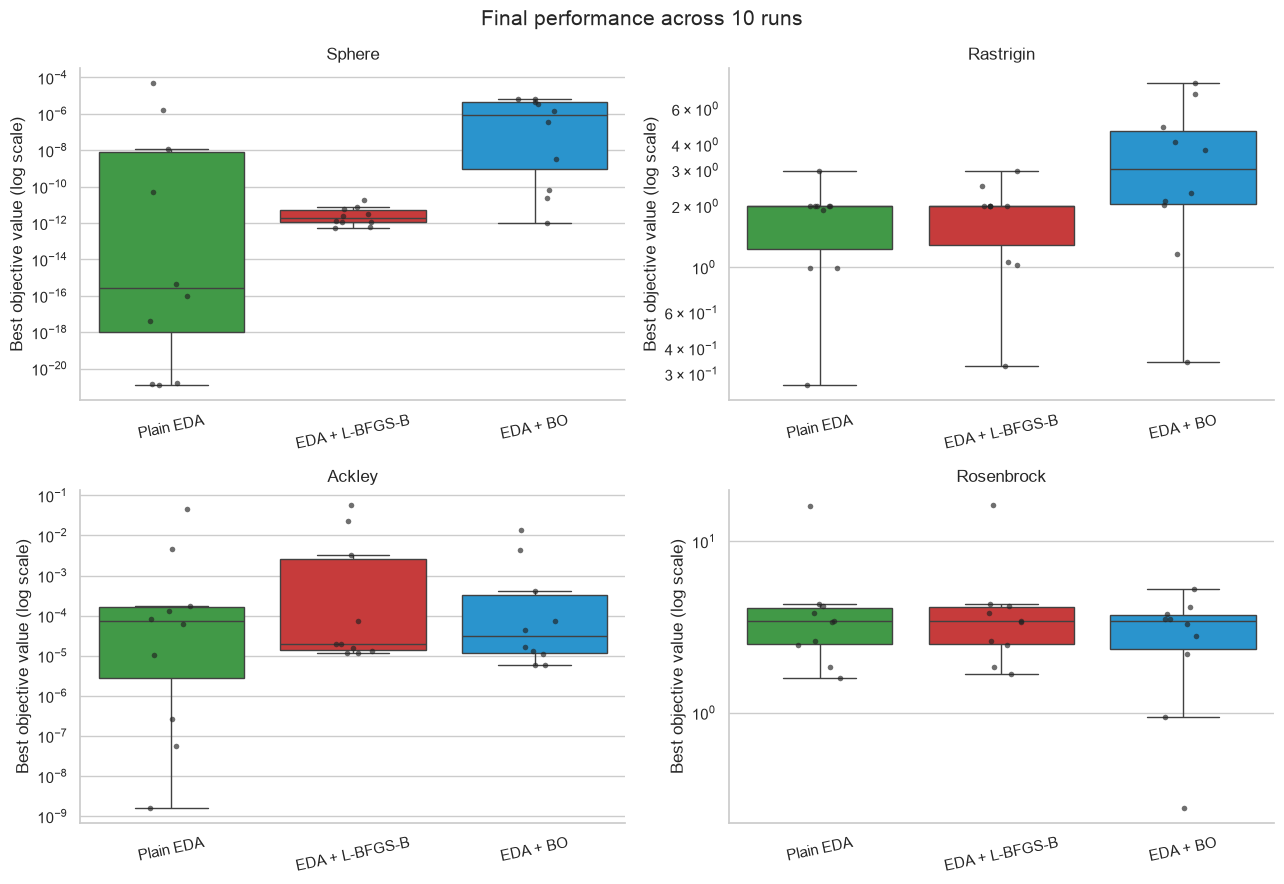

In [81]:
METHOD_COLORS = {
    "Plain EDA": "#32A83A",
    "EDA + L-BFGS-B": "#DD2424",
    "EDA + BO": "#0F9CE8",
}
positive_min = all_results.loc[all_results["best_value"] > 0, "best_value"].min()
plot_results = all_results.assign(
    plot_value=all_results["best_value"].clip(lower=positive_min / 10)
)

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, benchmark in zip(axes.flat, BENCHMARK_ORDER):
    data = plot_results[plot_results["benchmark"] == benchmark]
    sns.boxplot(
        data=data, x="method", y="plot_value", order=METHOD_ORDER,
        hue="method", palette=METHOD_COLORS, dodge=False,
        showfliers=False, legend=False, ax=ax,
    )
    sns.stripplot(
        data=data, x="method", y="plot_value", order=METHOD_ORDER,
        color="#222222", size=4, alpha=0.65, jitter=0.12, ax=ax,
    )
    ax.set_yscale("log")
    ax.set_title(benchmark.capitalize())
    ax.set_xlabel("")
    ax.set_ylabel("Best objective value (log scale)")
    ax.tick_params(axis="x", rotation=12)

fig.suptitle("Final performance across 10 runs", fontsize=15)
sns.despine()
plt.tight_layout()
plt.show()

## Paired wins over the plain EDA

This chart compares identical seeds and counts how often each local-search method achieves a lower final objective value than the plain EDA.

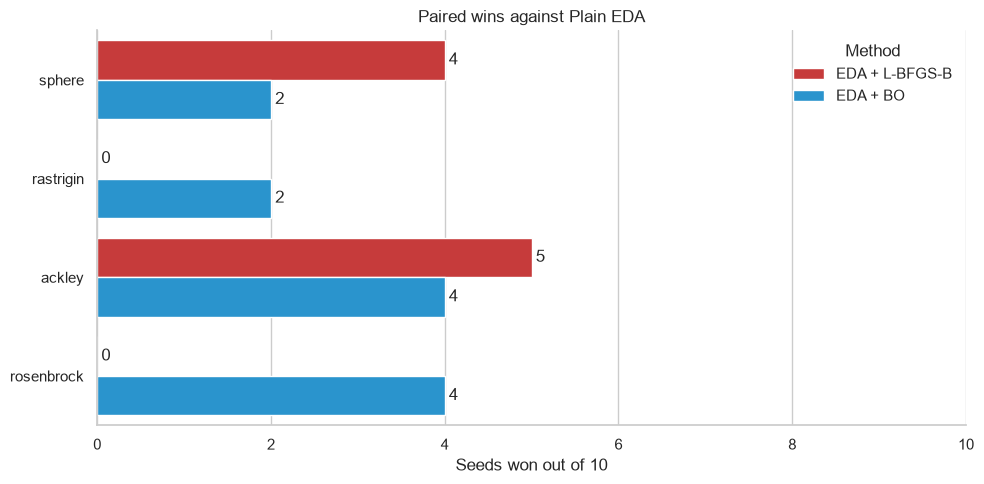

In [82]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(
    data=paired_summary,
    x="wins_vs_plain",
    y="benchmark",
    order=BENCHMARK_ORDER,
    hue="method",
    hue_order=METHOD_ORDER[1:],
    palette=METHOD_COLORS,
    ax=ax,
)
for container in ax.containers:
    ax.bar_label(container, fmt="%d", padding=3)
ax.set_xlim(0, N_RUNS)
ax.set_title("Paired wins against Plain EDA")
ax.set_xlabel("Seeds won out of 10")
ax.set_ylabel("")
ax.legend(title="Method", frameon=False)
sns.despine()
plt.tight_layout()
plt.show()